In [2]:
# Import libraries for data analysis

import pandas as pd
import numpy as np

# Import libraries for visualization

import matplotlib.pyplot as plt
import seaborn as sns

# Import functions for splitting the dataset

from sklearn.model_selection import train_test_split

# Import the Random Forest algorithm

from sklearn.ensemble import RandomForestClassifier

# Import evaluation metrics

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve
)

# Import hyperparameter tuning

from sklearn.model_selection import GridSearchCV

# Import warning handling

import warnings
warnings.filterwarnings("ignore")

print("All libraries imported successfully!")

All libraries imported successfully!
All libraries imported successfully!


In [4]:
# Load the uploaded CSV file

df = pd.read_csv("/content/WA_Fn-UseC_-Telco-Customer-Churn (1).csv")

# Display the first five rows

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
# Display the number of rows and columns

print("Dataset shape:", df.shape)

# Display column names

print("\nColumn names:")

print(df.columns.tolist())

# Display the first five rows

display(df.head())

Dataset shape: (7043, 21)

Column names:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [7]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [8]:
# Count the number of customers in each churn category

print(df["Churn"].value_counts())

# Calculate the percentage of each category

print("\nChurn percentage:")

print(
    df["Churn"].value_counts(normalize=True) * 100
)

Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn percentage:
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


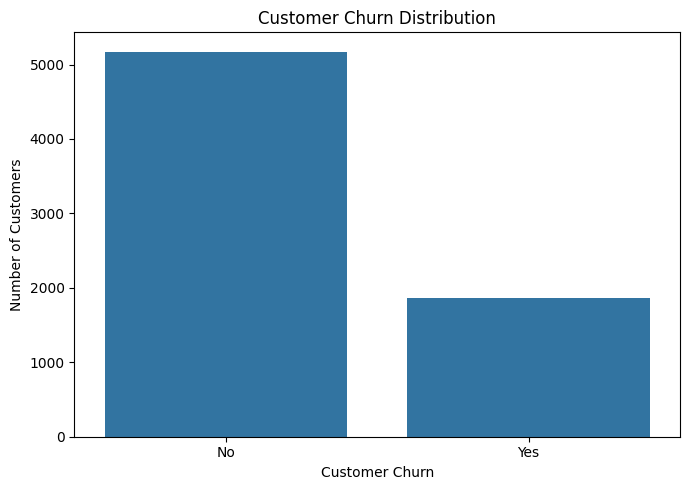

In [9]:
# Plot the distribution of customer churn

plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Churn"
)

plt.title("Customer Churn Distribution")

plt.xlabel("Customer Churn")

plt.ylabel("Number of Customers")

plt.tight_layout()

plt.show()

In [10]:
# Count missing values in each column

print(df.isnull().sum())

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [11]:
# Count duplicate rows

print(
    "Duplicate rows:",
    df.duplicated().sum()
)

Duplicate rows: 0


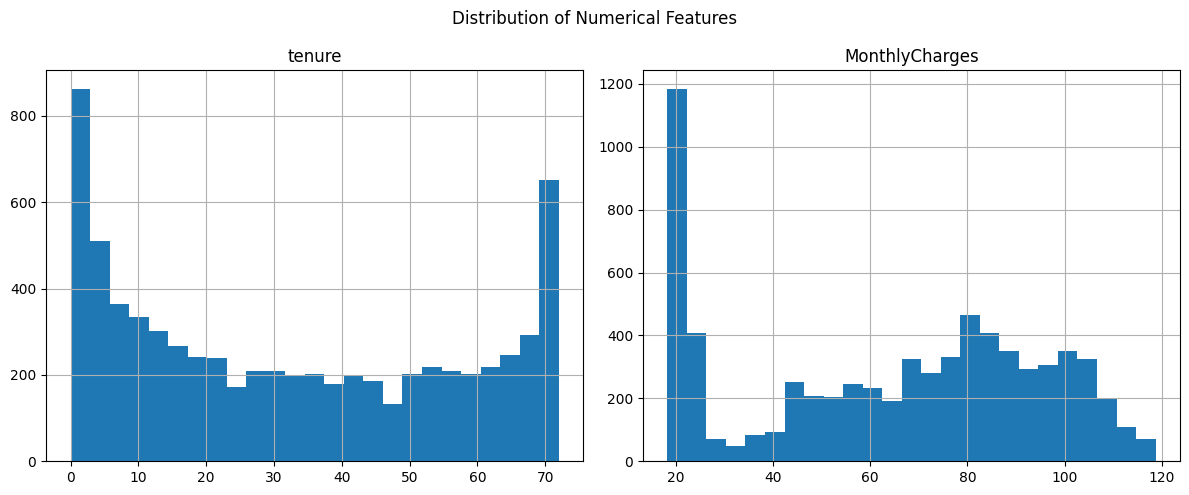

In [12]:
# Select numerical features

numerical_features = [
    "tenure",
    "MonthlyCharges"
]

# Plot their distributions

df[numerical_features].hist(
    figsize=(12, 5),
    bins=25
)

plt.suptitle("Distribution of Numerical Features")

plt.tight_layout()

plt.show()

In [13]:
# Convert TotalCharges to numeric values

df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

# Check missing values after conversion

print("Missing TotalCharges values:")

print(df["TotalCharges"].isnull().sum())

Missing TotalCharges values:
11


In [14]:
# Fill missing TotalCharges using the median

median_total_charges = df["TotalCharges"].median()

df["TotalCharges"] = df["TotalCharges"].fillna(
    median_total_charges
)

# Check the result

print(
    "Missing values after cleaning:",
    df["TotalCharges"].isnull().sum()
)

Missing values after cleaning: 0


In [15]:
# Check the number of unique customer IDs

print(
    "Unique customer IDs:",
    df["customerID"].nunique()
)

# Remove customerID

df = df.drop(
    columns=["customerID"]
)

# Display the updated dataset shape

print("Updated dataset shape:", df.shape)

Unique customer IDs: 7043
Updated dataset shape: (7043, 20)


In [16]:
# Display missing values in all columns

print(df.isnull().sum())

# Display data types

print("\nData types:")

print(df.dtypes)

# Display the first five cleaned rows

display(df.head())

gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Data types:
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Ch

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [17]:
# Separate input features and target variable

X = df.drop(
    columns=["Churn"]
)

y = df["Churn"].map({
    "No": 0,
    "Yes": 1
})

# Display feature and target shapes

print("Features shape:", X.shape)

print("Target shape:", y.shape)

# Check target encoding

print("\nTarget distribution:")

print(y.value_counts())

Features shape: (7043, 19)
Target shape: (7043,)

Target distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [18]:
# Import preprocessing tools

from sklearn.compose import ColumnTransformer

from sklearn.pipeline import Pipeline

from sklearn.preprocessing import OneHotEncoder

from sklearn.impute import SimpleImputer

# Identify numerical and categorical columns

numerical_columns = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_columns = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical columns:", numerical_columns)

print("\nCategorical columns:", categorical_columns)

Numerical columns: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical columns: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [19]:
# Create the numerical preprocessing pipeline

numerical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    )
])

# Create the categorical preprocessing pipeline

categorical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="most_frequent")
    ),
    (
        "encoder",
        OneHotEncoder(handle_unknown="ignore")
    )
])

# Combine both preprocessing pipelines

preprocessor = ColumnTransformer([
    (
        "numerical",
        numerical_pipeline,
        numerical_columns
    ),
    (
        "categorical",
        categorical_pipeline,
        categorical_columns
    )
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [20]:
# Split data into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display the sizes of the datasets

print("Training data:", X_train.shape)

print("Testing data:", X_test.shape)

print("\nTraining target distribution:")

print(y_train.value_counts())

print("\nTesting target distribution:")

print(y_test.value_counts())

Training data: (5634, 19)
Testing data: (1409, 19)

Training target distribution:
Churn
0    4139
1    1495
Name: count, dtype: int64

Testing target distribution:
Churn
0    1035
1     374
Name: count, dtype: int64


In [21]:
# Create the complete Random Forest pipeline

rf_model = Pipeline([
    (
        "preprocessor",
        preprocessor
    ),
    (
        "classifier",
        RandomForestClassifier(
            n_estimators=200,
            max_depth=None,
            random_state=42,
            class_weight="balanced",
            n_jobs=-1
        )
    )
])

# Train the model

rf_model.fit(
    X_train,
    y_train
)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [23]:
# Predict churn labels

y_pred = rf_model.predict(
    X_test
)

# Predict probabilities of churn

y_prob = rf_model.predict_proba(
    X_test
)[:, 1]

# Display actual and predicted values

comparison = pd.DataFrame({
    "Actual_Churn": y_test.values,
    "Predicted_Churn": y_pred
})

display(comparison.head(10))

,Actual_Churn,Predicted_Churn
0,0,0
1,0,1
2,0,0
3,0,0
4,0,0
5,0,0
6,0,0
7,0,0
8,0,0
9,1,0


In [24]:
# Calculate accuracy

accuracy = accuracy_score(
    y_test,
    y_pred
)

print("Accuracy:", round(accuracy, 4))

print(
    "Accuracy percentage:",
    round(accuracy * 100, 2),
    "%"
)

Accuracy: 0.785
Accuracy percentage: 78.5 %


In [25]:
# Calculate churn-focused evaluation metrics

precision = precision_score(
    y_test,
    y_pred,
    pos_label=1,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    pos_label=1,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    pos_label=1,
    zero_division=0
)

print("Precision:", round(precision, 4))

print("Recall:", round(recall, 4))

print("F1-Score:", round(f1, 4))

Precision: 0.6246
Recall: 0.4759
F1-Score: 0.5402


In [26]:
# Display evaluation metrics for both classes

print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "No Churn",
            "Churn"
        ],
        zero_division=0
    )
)

              precision    recall  f1-score   support

    No Churn       0.83      0.90      0.86      1035
       Churn       0.62      0.48      0.54       374

    accuracy                           0.78      1409
   macro avg       0.73      0.69      0.70      1409
weighted avg       0.77      0.78      0.77      1409



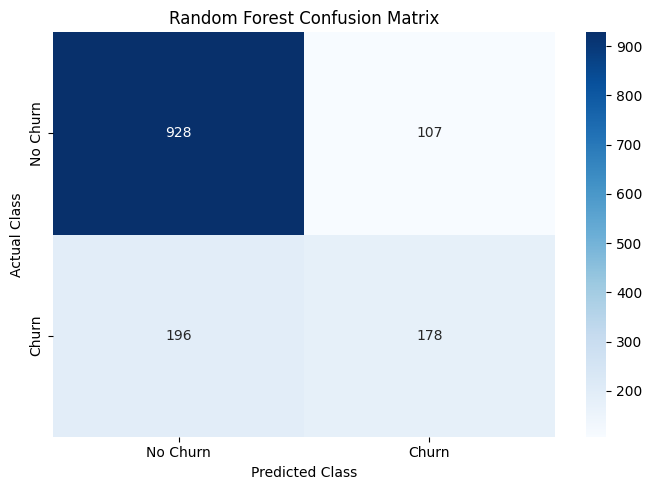

In [27]:
# Calculate the confusion matrix

cm = confusion_matrix(
    y_test,
    y_pred
)

# Plot the confusion matrix

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "No Churn",
        "Churn"
    ],
    yticklabels=[
        "No Churn",
        "Churn"
    ]
)

plt.title("Random Forest Confusion Matrix")

plt.xlabel("Predicted Class")

plt.ylabel("Actual Class")

plt.tight_layout()

plt.show()

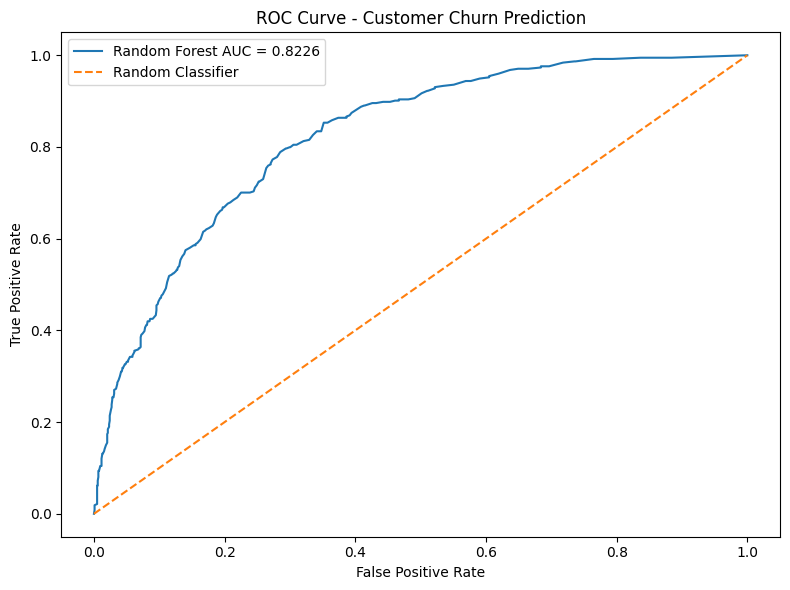

ROC-AUC Score: 0.8226


In [28]:
# Calculate the ROC curve

fpr, tpr, thresholds = roc_curve(
    y_test,
    y_prob
)

# Calculate ROC-AUC

auc_score = roc_auc_score(
    y_test,
    y_prob
)

# Plot the ROC curve

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Random Forest AUC = {auc_score:.4f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")

plt.ylabel("True Positive Rate")

plt.title("ROC Curve - Customer Churn Prediction")

plt.legend()

plt.tight_layout()

plt.show()

print("ROC-AUC Score:", round(auc_score, 4))

In [29]:
# Get the trained preprocessing pipeline

fitted_preprocessor = rf_model.named_steps[
    "preprocessor"
]

# Get the trained Random Forest classifier

fitted_classifier = rf_model.named_steps[
    "classifier"
]

# Retrieve the encoded feature names

feature_names = fitted_preprocessor.get_feature_names_out()

# Retrieve feature importance scores

importance_values = fitted_classifier.feature_importances_

# Create a feature importance DataFrame

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
})

# Sort by importance

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Display the top 15 features

display(
    feature_importance.head(15)
)

,Feature,Importance
3,numerical__TotalCharges,0.142966
1,numerical__tenure,0.130728
2,numerical__MonthlyCharges,0.122605
36,categorical__Contract_Month-to-month,0.069657
18,categorical__OnlineSecurity_No,0.039620
38,categorical__Contract_Two year,0.034687
27,categorical__TechSupport_No,0.034413
43,categorical__PaymentMethod_Electronic check,0.029161
16,categorical__InternetService_Fiber optic,0.027392
21,categorical__OnlineBackup_No,0.017552


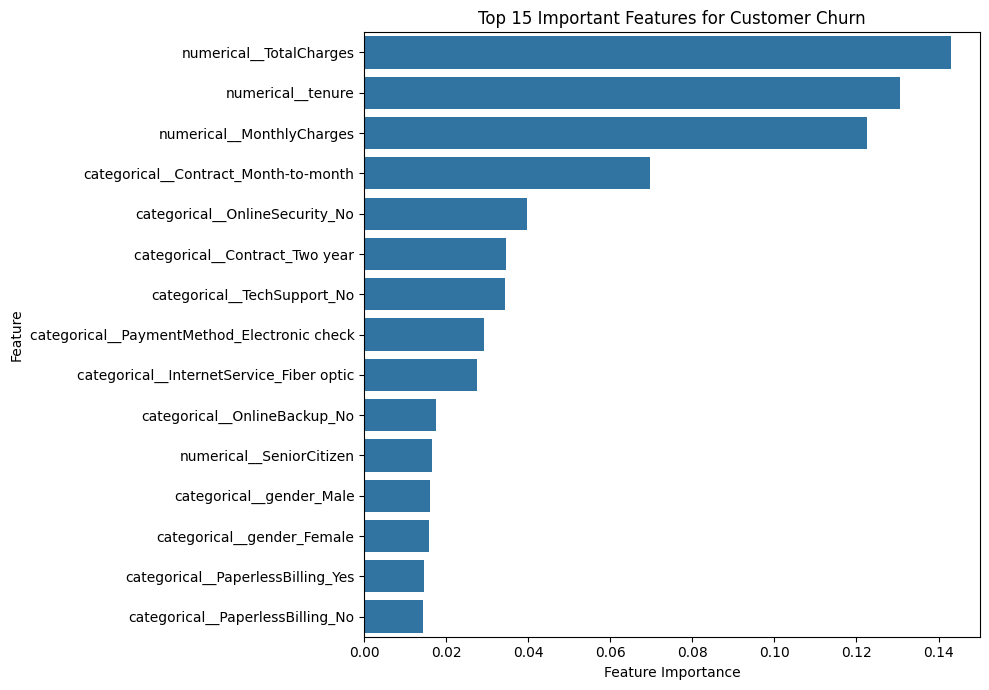

In [30]:
# Plot the top 15 important features

top_features = feature_importance.head(15)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Important Features for Customer Churn")

plt.xlabel("Feature Importance")

plt.ylabel("Feature")

plt.tight_layout()

plt.show()

In [31]:
# Create a summary of model evaluation metrics

results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "ROC-AUC"
    ],
    "Score": [
        accuracy,
        precision,
        recall,
        f1,
        auc_score
    ]
})

display(results)

,Metric,Score
0,Accuracy,0.784954
1,Precision,0.624561
2,Recall,0.475936
3,F1-Score,0.540212
4,ROC-AUC,0.822602


In [32]:
# Define a small parameter grid

param_grid = {
    "classifier__n_estimators": [100, 200],
    "classifier__max_depth": [10, None],
    "classifier__min_samples_split": [2, 5]
}

# Initialize GridSearchCV

grid_search = GridSearchCV(
    estimator=rf_model,
    param_grid=param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1,
    verbose=1
)

# Perform hyperparameter tuning using training data only

grid_search.fit(
    X_train,
    y_train
)

# Display the best parameter combination

print("Best Parameters:")

print(grid_search.best_params_)

print("\nBest Cross-Validation F1-Score:")

print(grid_search.best_score_)

Fitting 5 folds for each of 8 candidates, totalling 40 fits
Best Parameters:
{'classifier__max_depth': 10, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 200}

Best Cross-Validation F1-Score:
0.6325493556013189


In [33]:
# Get the best tuned model

best_model = grid_search.best_estimator_

# Predict churn using the tuned model

y_pred_tuned = best_model.predict(
    X_test
)

# Calculate the tuned model metrics

print(
    "Tuned Accuracy:",
    accuracy_score(y_test, y_pred_tuned)
)

print(
    "\nTuned Precision:",
    precision_score(
        y_test,
        y_pred_tuned,
        zero_division=0
    )
)

print(
    "Tuned Recall:",
    recall_score(
        y_test,
        y_pred_tuned,
        zero_division=0
    )
)

print(
    "Tuned F1-Score:",
    f1_score(
        y_test,
        y_pred_tuned,
        zero_division=0
    )
)

print(
    "\nTuned ROC-AUC:",
    roc_auc_score(
        y_test,
        best_model.predict_proba(X_test)[:, 1]
    )
)

Tuned Accuracy: 0.7629524485450674

Tuned Precision: 0.542016806722689
Tuned Recall: 0.6898395721925134
Tuned F1-Score: 0.6070588235294118

Tuned ROC-AUC: 0.8379046216642125


In [34]:
# Import joblib

import joblib

# Save the tuned model

joblib.dump(
    best_model,
    "telco_customer_churn_random_forest.pkl"
)

print("Trained model saved successfully!")

Trained model saved successfully!


In [35]:
from google.colab import files

files.download(
    "telco_customer_churn_random_forest.pkl"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [36]:
plt.savefig(
    "confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>